# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿podemos convertir documentos escaneados y entrevistas en audio peruanos en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de extracción** | 25 de octubre de 2026 (descarga, OCR y transcripción) |
| **Documentos (25)** | 8 impresos, 8 fotos y 9 manuscritos. 18 de [Wikimedia Commons](https://commons.wikimedia.org) (dominio público, CC0, CC BY 2.0/3.0/4.0, CC BY-SA 3.0/4.0), 1 del [Archivo José Carlos Mariátegui](https://archivo.mariategui.org) (dominio público; libre descarga según el archivo) y 6 fotos propias de manuscritos (sin datos personales; texto seudonimizado) |
| **Audio (25 clips, ~50 min)** | 17 entrevistas y testimonios en español peruano de Wikimedia Commons (CC BY 4.0 y CC BY-SA 4.0) y 8 frases leídas de [OpenSLR 73](https://www.openslr.org/73/) (Google, CC BY-SA 4.0) |
| **OCR** | PaddleOCR 3.7.0 · PP-OCRv6_medium (detección + reconocimiento), `lang="es"`, PaddlePaddle 3.3.1 en CPU |
| **ASR** | faster-whisper 1.2.1 · Whisper large-v3-turbo (int8, CPU) con VAD Silero · diarización con WeSpeaker ResNet34 (pyannote-audio 4.0.7) |
| **Atribución completa** | `datos/fuentes.csv`: URL, licencia, autor y forma de acceso de cada uno de los 50 archivos |

**Entorno.** En lugar de `uv sync --group docai/audio` del repo del curso se usó un entorno propio con las mismas librerías y versiones exactas: `python3.12 -m venv .venv && .venv/bin/pip install -r requirements-pipeline.txt` (macOS arm64).

**Flujo y archivos.**

1. `descargar_corpus.py` baja el corpus a `datos/raw/` (no se versiona) y escribe `datos/fuentes.csv`.
2. `ocr.py` contiene el OCR con PaddleOCR: guarda un respaldo crudo por documento (`datos/raw/documentos/ocr/*.json`) y los recortes de cada línea (`datos/raw/documentos/recortes/`).
3. `asr.py` contiene VAD + faster-whisper + diarización + seudonimización y exporta SRT, TXT y JSON por clip a `datos/raw/audio/salidas/`.
4. Este notebook **ejecuta el OCR y el ASR** llamando a las funciones de `ocr.py` y `asr.py`. Después seudonimiza, limpia, explora y exporta `datos/documentos.csv`, `datos/transcripciones.csv` y `datos/fuentes.csv`.

**Seudonimización.** Los nombres reales que hay que ocultar están en `datos/raw/seudonimos.json`, fuera de Git porque contiene justamente esos nombres. Aquí solo se reportan cuántas entidades se reemplazaron.

In [1]:
import hashlib
import json
import os
import time
from importlib.metadata import version
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio
from PIL import Image

os.environ.setdefault("ASR_HILOS", "8")   # hilos de CPU para faster-whisper (se lee al importar asr)
import asr   # VAD + faster-whisper + diarización + seudonimización (asr.py)
import ocr   # OCR con PaddleOCR (ocr.py)

# Plotly interactivo en Jupyter + una copia PNG para que los gráficos se vean en GitHub
pio.renderers.default = "notebook_connected+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 520
pio.templates.default = "plotly_white"
COLORES = {"impreso": "#2a78d6", "foto": "#eb6834", "manuscrito": "#0ca30c"}

pd.set_option("display.max_colwidth", 90)
DATOS = Path("datos")

for paquete in ["paddleocr", "paddlepaddle", "faster-whisper", "ctranslate2", "pyannote-audio", "torch", "plotly", "pandas"]:
    print(f"{paquete:<15} {version(paquete)}")

paddleocr       3.7.0
paddlepaddle    3.3.1
faster-whisper  1.2.1
ctranslate2     4.8.3
pyannote-audio  4.0.7
torch           2.14.1
plotly          7.1.0
pandas          3.1.0


In [2]:
fuentes = pd.read_csv(DATOS / "fuentes.csv")
print(f"fuentes.csv: {fuentes.shape[0]} archivos")
fuentes.groupby(["modalidad", "tipo", "licencia"]).size().rename("archivos").to_frame()

fuentes.csv: 50 archivos


archivos
modalidad tipo       licencia                                                                         
audio     entrevista CC BY 4.0                                                                       3
                     CC BY-SA 4.0                                                                   14
          lectura    CC BY-SA 4.0                                                                    8
documento foto       CC BY 3.0                                                                       1
                     CC BY-SA 3.0                                                                    2
                     CC BY-SA 4.0                                                                    5
          impreso    Public domain                                                                   8
          manuscrito CC BY 2.0                                                                       1
                     Captura propia (Ximena Pinillos), sin datos personales                          6
                     Dominio público; libre descarga según el Archivo José Carlos Mariátegui         1
                     Public domain                                                                   1

## 1 · Documentos: OCR con PaddleOCR (Sesión 10)

Las funciones están en `ocr.py`; aquí se ejecutan. La configuración es la misma para los 25 documentos y se fijó **antes** de mirar los resultados (no se ajustó nada por documento):

- **Modelo:** PaddleOCR 3.7 con PP-OCRv6_medium para detectar y reconocer líneas, motor PaddlePaddle en CPU.
- **Idioma:** `lang="es"`.
- **Preprocesamiento:** ninguno. No se usa clasificador de orientación, ni «planchado» de la hoja, ni giro por línea (igual que en la clase). La única transformación es la de la descarga: máximo 1920 px de ancho, RGB y sin metadatos EXIF.

**Salidas en `datos/raw/documentos/`** (no se versionan): `ocr/doc_XXX.json`, el respaldo crudo con el texto, la confianza y la caja de cada línea; y `recortes/doc_XXX/linea_NNN.jpg`, una imagen por línea detectada.

`REHACER_OCR = True` vuelve a leer los 25 documentos aunque ya exista su JSON. Con `False` se retoman los guardados.

In [3]:
REHACER_OCR = True

print("Parámetros de PaddleOCR:", ocr.OPCIONES)
docs = fuentes[fuentes["modalidad"] == "documento"].reset_index(drop=True)
rutas = [Path(a) for a in docs["archivo"]]

t0 = time.perf_counter()
motor_ocr = ocr.crear_ocr()
print(f"Modelo cargado en {time.perf_counter() - t0:.1f} s · {ocr.descripcion_modelo()}")

Parámetros de PaddleOCR: {'lang': 'es', 'device': 'cpu', 'use_doc_orientation_classify': False, 'use_doc_unwarping': False, 'use_textline_orientation': False}


Modelo cargado en 6.6 s · PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, CPU, sin preprocesamiento)


In [4]:
t0 = time.perf_counter()
crudo = ocr.procesar(rutas, motor_ocr, rehacer=set(docs["id"]) if REHACER_OCR else set())
print(f"\nOCR de {len(crudo)} documentos en {(time.perf_counter() - t0) / 60:.1f} min")

  doc_001: 124 líneas · confianza media 0.96 ·   72.9 s


  doc_002:  45 líneas · confianza media 0.93 ·   43.9 s


  doc_003:  44 líneas · confianza media 0.94 ·   49.0 s


  doc_004:  45 líneas · confianza media 0.92 ·   44.0 s


  doc_005:  34 líneas · confianza media 0.86 ·   25.8 s


...

  doc_022:  36 líneas · confianza media 0.93 ·   22.0 s


  doc_023:  12 líneas · confianza media 0.88 ·   10.9 s


  doc_024:  25 líneas · confianza media 0.95 ·   20.9 s


  doc_025:  22 líneas · confianza media 0.95 ·   16.3 s



OCR de 25 documentos en 11.9 min


In [5]:
docs["lineas"] = docs["id"].map(lambda i: len(crudo[i]["lineas"]))
docs["confianza_media"] = docs["id"].map(
    lambda i: pd.Series([l["confianza"] for l in crudo[i]["lineas"]], dtype=float).mean())
docs["lineas_conf_baja"] = docs["id"].map(lambda i: sum(l["confianza"] < 0.70 for l in crudo[i]["lineas"]))
docs["segundos_ocr"] = docs["id"].map(lambda i: crudo[i]["segundos"])
docs["recortes"] = docs["id"].map(lambda i: len(list((ocr.RECORTES / i).glob("linea_*.jpg"))))
docs["texto_crudo"] = docs["id"].map(lambda i: ocr.texto(crudo[i]))
MODELO_OCR = crudo[docs["id"].iloc[0]]["modelo_ocr"]

print(f"{len(docs)} documentos · {docs['lineas'].sum()} líneas · {docs['recortes'].sum()} recortes guardados")
display(docs.groupby("tipo")[["lineas", "confianza_media", "segundos_ocr"]].agg(["mean", "min", "max"]).round(2))
docs[["id", "tipo", "descripcion", "lineas", "confianza_media", "lineas_conf_baja", "segundos_ocr"]].round(2)

25 documentos · 762 líneas · 762 recortes guardados


lineas          confianza_media             segundos_ocr         \
             mean min  max            mean   min   max         mean    min   
tipo                                                                         
foto        13.38   7   28            0.96  0.92  0.99        19.97  12.96   
impreso     60.38   9  154            0.89  0.68  0.99        49.78  11.20   
manuscrito  19.11  12   36            0.90  0.81  0.95        17.39   6.73   

                   
              max  
tipo               
foto        34.27  
impreso     91.56  
manuscrito  31.69

,id,tipo,descripcion,lineas,confianza_media,lineas_conf_baja,segundos_ocr
0,doc_001,impreso,"El Comercio, edición del 3 de marzo de 1842",124,0.96,1,72.90
1,doc_002,impreso,"Mercurio Peruano (1791), «Carta sobre los maricones», p. 1",45,0.93,1,43.86
2,doc_003,impreso,"Mercurio Peruano (1791), «Carta sobre los maricones», p. 2",44,0.94,1,48.99
3,doc_004,impreso,"Mercurio Peruano (1791), «Carta sobre los maricones», p. 3",45,0.92,0,44.02
4,doc_005,impreso,Portada del Mercurio Peruano,34,0.86,3,25.83
5,doc_006,impreso,"Portada de la revista Amauta, n.º 1 (1926)",28,0.99,0,59.85
6,doc_007,impreso,Primer número de El Comercio (1839),154,0.68,99,91.56
7,doc_008,impreso,Crónica de un partido de fútbol en El Comercio (1904),9,0.89,1,11.20
8,doc_009,foto,Pizarra de menú,7,0.92,0,15.53
9,doc_010,foto,Cartel de la cevichería El Tiburón,10,0.96,0,12.96


,texto,confianza,caja
0,ENTRADAS,0.8302,"[191, 66, 720, 292]"
1,SEGUNDOS,0.9893,"[768, 107, 1228, 256]"
2,Postres,0.9997,"[1305, 142, 1678, 287]"
3,Gnocchi,0.9943,"[163, 246, 529, 419]"
4,TacuTacy+,0.8335,"[773, 261, 1207, 429]"
5,*Strudelde,0.9706,"[1271, 294, 1698, 417]"


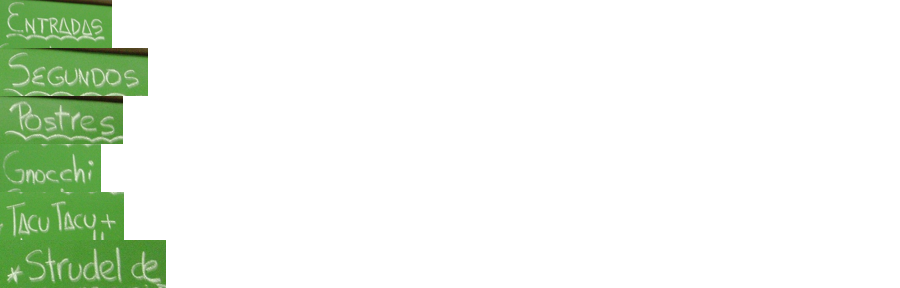

In [6]:
# Un ejemplo del respaldo crudo y de los recortes: las primeras líneas de la pizarra de menú (doc_014)
ejemplo = pd.DataFrame(crudo["doc_014"]["lineas"]).head(6)
display(ejemplo)
recortes = sorted((ocr.RECORTES / "doc_014").glob("linea_*.jpg"))[:6]
alto = 48
tira = Image.new("RGB", (900, alto * len(recortes)), "white")
for k, r in enumerate(recortes):
    im = Image.open(r)
    im = im.resize((min(900, int(im.width * alto / im.height)), alto))
    tira.paste(im, (0, k * alto))
tira

## 2 · Limpieza: duplicados por hash y descartes

- **Duplicados:** se compara el SHA-256 de cada imagen; dos archivos con el mismo hash son la misma imagen.
- **Descartes:** se descarta un documento ilegible o del que el OCR no extrae ninguna línea, y se reemplaza por otro del mismo tipo para mantener los mínimos (8/8/9).

In [7]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

docs["sha256"] = docs["archivo"].map(sha256)
duplicados = docs[docs["sha256"].duplicated(keep=False)]
print(f"Duplicados exactos por hash: {len(duplicados)}")

# Descartes ya aplicados durante la construcción del corpus (registrados aquí para el reporte)
descartes_docs = pd.DataFrame([{
    "id": "doc_016 (primera versión)",
    "tipo": "foto",
    "archivo_descartado": "Cartel Picante de cuy.JPG (Wikimedia Commons, dominio público)",
    "motivo": "PaddleOCR no detectó ninguna línea (0 líneas): letras pintadas a mano muy grandes, de dos colores, sobre fondo negro",
    "reemplazo": "Cartel - Plaza de los Peregrinos.jpg (Wikimedia Commons, CC BY-SA 4.0)",
}])
sin_texto = docs[docs["lineas"] == 0]
print(f"Documentos actuales sin ninguna línea detectada: {len(sin_texto)}")
descartes_docs

Duplicados exactos por hash: 0
Documentos actuales sin ninguna línea detectada: 0


,id,tipo,archivo_descartado,motivo,reemplazo
0,doc_016 (primera versión),foto,"Cartel Picante de cuy.JPG (Wikimedia Commons, dominio público)","PaddleOCR no detectó ninguna línea (0 líneas): letras pintadas a mano muy grandes, de ...","Cartel - Plaza de los Peregrinos.jpg (Wikimedia Commons, CC BY-SA 4.0)"


El cartel «Picante de cuy» es perfectamente legible para una persona; el problema es del **detector**. Lo que el detector no ve no aparece con confianza baja: simplemente falta, y ninguna alarma suena. Por eso se reporta como descarte del corpus y se analiza como caso difícil en la Parte 2.

## 3 · Seudonimización de los textos OCR

Criterio:

- **Documentos históricos de dominio público** (Mercurio Peruano de 1791, El Comercio, Amauta, Mariátegui, Guamán Poma...). Sus nombres son de personajes públicos ya fallecidos y forman parte del contenido histórico, así que no se reemplazan. Por eso se apaga la detección automática por contexto («señor», «don»...), que aquí daría falsos positivos.
- **Fotos propias** (`doc_020`–`doc_025`). Se revisó cada imagen a mano y los nombres de personas privadas se agregaron, con las variantes que produjo el OCR, a `datos/raw/seudonimos.json`. Esa lista se aplica **solo a estas fotos**: en una primera prueba, aplicada a todo el corpus, la comparación difusa confundió uno de esos nombres con una palabra mal leída (ruido del OCR) de El Comercio de 1839.
- **En todos los documentos** se buscan además DNI (8 dígitos), celulares (9 dígitos que empiezan en 9) y cuentas `@usuario`.

Cada persona se reemplaza por `[PERSONA_N]`, con el mismo N en todo el corpus.

In [8]:
seud_propias = asr.Seudonimizador(asr.cargar_personas("personas_documentos"), por_contexto=False)
seud_resto = asr.Seudonimizador([], por_contexto=False)       # solo DNI, celulares y cuentas @
propia = docs["licencia"].str.startswith("Captura propia")

conteos = []
textos = {}
for fila, es_propia in zip(docs.itertuples(), propia):
    texto, cuenta = (seud_propias if es_propia else seud_resto).aplicar(fila.texto_crudo)
    textos[fila.id] = texto
    conteos.append({"id": fila.id, **cuenta})
docs["texto_ocr"] = docs["id"].map(textos)

conteos = pd.DataFrame(conteos).set_index("id")
conteos["total"] = conteos.sum(axis=1)
print(f"Entidades reemplazadas en los documentos: {conteos['total'].sum()} "
      f"({conteos['nombre'].sum()} nombres, {conteos['usuario'].sum()} cuentas, "
      f"{conteos['dni'].sum()} DNI, {conteos['celular'].sum()} celulares) "
      f"en {(conteos['total'] > 0).sum()} documentos")
conteos[conteos["total"] > 0]

Entidades reemplazadas en los documentos: 4 (3 nombres, 1 cuentas, 0 DNI, 0 celulares) en 2 documentos


,nombre,dni,celular,usuario,total
id,,,,,
doc_022,2,0,0,1,3
doc_023,1,0,0,0,1


## 4 · Exportación de `datos/documentos.csv`

Se guarda con las columnas exactas del enunciado. `texto_referencia` queda vacía: se completa en la Parte 2, solo para los 10 documentos de la muestra de evaluación.

In [9]:
def origen(fila):
    if "commons.wikimedia.org" in str(fila.fuente_url):
        return f"Wikimedia Commons ({fila.licencia})"
    if "mariategui.org" in str(fila.fuente_url):
        return f"Archivo José Carlos Mariátegui ({fila.licencia})"
    return "Captura propia (sin datos personales; texto seudonimizado)"

documentos = pd.DataFrame({
    "id": docs["id"],
    "archivo": docs["archivo"],
    "tipo": docs["tipo"],
    "fuente": [origen(f) for f in docs.itertuples()],
    "texto_ocr": docs["texto_ocr"],
    "modelo_ocr": MODELO_OCR,
    "texto_referencia": None,
})
documentos.to_csv(DATOS / "documentos.csv", index=False)
print("documentos.csv:", documentos.shape)
documentos.head(5)

documentos.csv: (25, 7)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (Public domain),EL COMERCIO\n826\nras siendo el numero ultimo 183.\nS e está esperando un decreto del ...,"PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, CPU, sin preprocesamiento)",None
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (Public domain),"230.\nde heber tenido tan buen discernimiento, que haya merecido \nprobacion Dios guar...","PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, CPU, sin preprocesamiento)",None
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (Public domain),"431.\neuerpo: dirigen ácía todas partes sus miradas con un desmayo\nafectado, y con ta...","PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, CPU, sin preprocesamiento)",None
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (Public domain),"desa Trifaldi: á este tiempo llegaren de Sera sas-mademizas de\n332.\neñe jaez, levast...","PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, CPU, sin preprocesamiento)",None
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (Public domain),ENES\nFol. r\n\nNum. I.\nや00\nMERCURIO PERUANO\nDEL DIA 2. DE ENERO DE 1791.\nIDEA CEN...,"PaddleOCR 3.7.0 (PP-OCRv6_medium det+rec, lang=es, CPU, sin preprocesamiento)",None


## 5 · Análisis exploratorio de los documentos

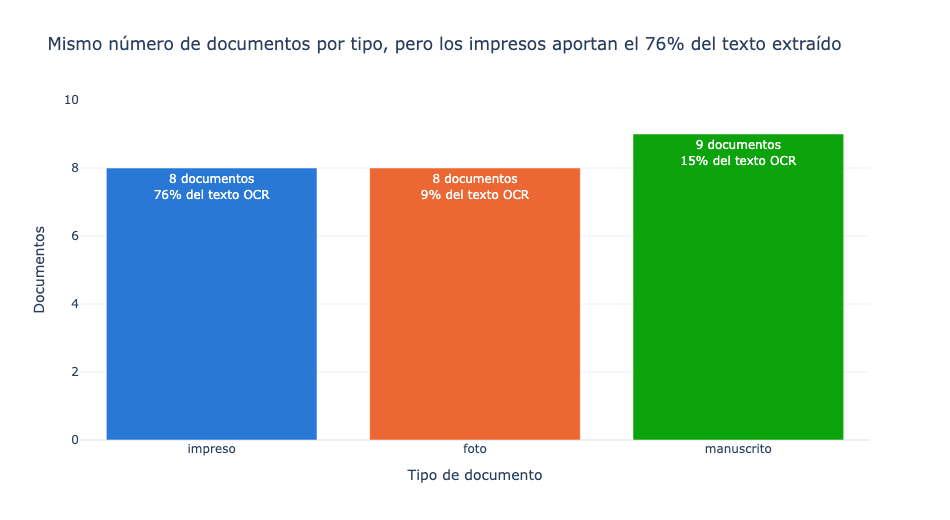

,documentos,caracteres,% del texto
tipo,,,
impreso,8,22346,76.4
foto,8,2575,8.8
manuscrito,9,4317,14.8


In [10]:
docs["caracteres"] = docs["texto_ocr"].str.len()
docs["palabras"] = docs["texto_ocr"].str.split().str.len()

por_tipo = docs.groupby("tipo").agg(documentos=("id", "size"), caracteres=("caracteres", "sum")).reindex(["impreso", "foto", "manuscrito"])
por_tipo["% del texto"] = (100 * por_tipo["caracteres"] / por_tipo["caracteres"].sum()).round(1)
pct_impresos = por_tipo.loc["impreso", "% del texto"]

fig = px.bar(por_tipo.reset_index(), x="tipo", y="documentos", color="tipo", color_discrete_map=COLORES,
             text=[f"{d} documentos<br>{p:.0f}% del texto OCR" for d, p in zip(por_tipo["documentos"], por_tipo["% del texto"])],
             labels={"tipo": "Tipo de documento", "documentos": "Documentos"},
             title=f"Mismo número de documentos por tipo, pero los impresos aportan el {pct_impresos:.0f}% del texto extraído")
fig.update_traces(textposition="inside")
fig.update_layout(showlegend=False, yaxis_range=[0, 10])
fig.show()
por_tipo

**Gráfico 3 (longitud de los textos extraídos).** Combina los caracteres OCR por documento y las palabras ASR por clip. Aquí se muestra la mitad de documentos; el gráfico completo está en la sección de audio.

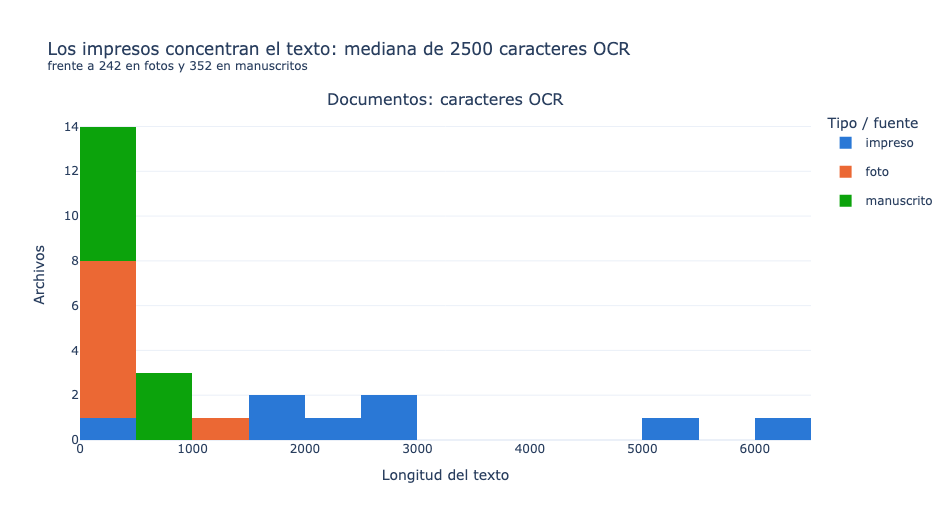

,min,50%,max
tipo,,,
foto,57.0,242.5,1079.0
impreso,416.0,2499.5,6007.0
manuscrito,204.0,352.0,870.0


In [11]:
def grafico_longitudes(docs, clips=None):
    # Caracteres OCR por documento y, si hay clips, palabras ASR por clip.
    # Cada panel es un px.histogram con sus propias barras (las escalas son muy distintas).
    from plotly.subplots import make_subplots
    med = docs.groupby("tipo")["caracteres"].median()
    paneles = [px.histogram(docs, x="caracteres", color="tipo", nbins=25, color_discrete_map=COLORES)]
    nombres = ["Documentos: caracteres OCR"]
    titulo = (f"Los impresos concentran el texto: mediana de {med['impreso']:.0f} caracteres OCR<br>"
              f"<sup>frente a {med['foto']:.0f} en fotos y {med['manuscrito']:.0f} en manuscritos</sup>")
    if clips is not None:
        paneles.append(px.histogram(clips, x="palabras", color="origen", nbins=25,
                                    color_discrete_map={"Wikimedia Commons": "#7b4fd6", "OpenSLR 73": "#898781"}))
        nombres.append("Audio: palabras ASR")
        mc = clips.groupby("origen")["palabras"].median()
        titulo = (f"Los impresos y las entrevistas concentran el texto<br><sup>Mediana OCR: {med['impreso']:.0f} caracteres "
                  f"en impresos vs {med['foto']:.0f} en fotos y {med['manuscrito']:.0f} en manuscritos · "
                  f"mediana ASR: {mc.get('Wikimedia Commons', 0):.0f} palabras por entrevista vs "
                  f"{mc.get('OpenSLR 73', 0):.0f} por frase leída</sup>")
    fig = make_subplots(rows=1, cols=len(paneles), subplot_titles=nombres, horizontal_spacing=0.08)
    for k, panel in enumerate(paneles, start=1):
        for traza in panel.data:
            fig.add_trace(traza.update(bingroup=f"panel{k}"), row=1, col=k)   # barras propias por panel
        fig.update_xaxes(title_text="Longitud del texto", row=1, col=k)
    fig.update_layout(barmode="stack", title=titulo, legend_title_text="Tipo / fuente", margin=dict(t=110))
    fig.update_yaxes(title_text="Archivos", row=1, col=1)
    return fig

grafico_longitudes(docs).show()
docs.groupby("tipo")["caracteres"].describe()[["min", "50%", "max"]]

## 6 · Validación: los 3 documentos con más y menos texto

In [12]:
cols = ["id", "tipo", "descripcion", "lineas", "caracteres", "confianza_media"]
vista = docs.assign(inicio_del_texto=docs["texto_ocr"].str.replace("\n", " / ").str[:120])
print("Más largos:")
display(vista.nlargest(3, "caracteres")[cols + ["inicio_del_texto"]].round(2))
print("Más cortos:")
display(vista.nsmallest(3, "caracteres")[cols + ["inicio_del_texto"]].round(2))

Más largos:


,id,tipo,descripcion,lineas,caracteres,confianza_media,inicio_del_texto
6,doc_007,impreso,Primer número de El Comercio (1839),154,6007,0.68,"Eate periidion se doepaenn dn este Capltal / Le ovive qoé deben spir an rd / das, y en..."
0,doc_001,impreso,"El Comercio, edición del 3 de marzo de 1842",124,5164,0.96,EL COMERCIO / 826 / ras siendo el numero ultimo 183. / S e está esperando un decreto d...
2,doc_003,impreso,"Mercurio Peruano (1791), «Carta sobre los maricones», p. 2",44,2637,0.94,"431. / euerpo: dirigen ácía todas partes sus miradas con un desmayo / afectado, y con ..."


Más cortos:


,id,tipo,descripcion,lineas,caracteres,confianza_media,inicio_del_texto
14,doc_015,foto,"Placa de la Calle Capón, Barrio Chino de Lima",9,57,0.93,Baby Boy / BARRIO / CHINO / GAS HELIO / CALLE / 10 / CAPON / BACKYARD / H
8,doc_009,foto,Pizarra de menú,7,105,0.92,Meniu / Aguadito de pollo / EsTofado de pollo cmenestra / Tallarin saltado / arroechau...
9,doc_010,foto,Cartel de la cevichería El Tiburón,10,138,0.96,CEVICHERIA / EL-TIBURON-1 / CEVICHEMIXTO / 9. suleche ol.Tigre / Canchita / Arroz Chau...


**Coherencia con el histograma.**
- Los tres documentos más largos son impresos de periódico, con miles de caracteres: forman la cola derecha del histograma.
- Los tres más cortos son fotos de carteles y pizarras, o manuscritos con poco texto, y quedan en la primera barra.
- No hay documentos con 0 caracteres, porque el único caso (el cartel «Picante de cuy») se reemplazó.

**Ojo con la longitud.** Más caracteres no significa mejor lectura. `doc_007` (El Comercio de 1839, escaneado a solo 500 px) es de los más largos, pero tiene la confianza más baja del corpus: mucho de su texto es ruido. El CER de la Parte 2 lo medirá.

## 7 · Audio: VAD + faster-whisper + diarización (Sesión 13)

Las funciones están en `asr.py` (adaptadas de `voz.py` de la Sesión 13); aquí se ejecutan. Configuración fija para los 25 clips:

- **VAD Silero activado** (`vad_filter=True`, pausas de 0,3 s). El silencio y la música sin voz no llegan a Whisper, lo que evita las alucinaciones típicas. Un clip con menos de 1 s de voz según el VAD se descarta como «sin voz».
- **Modelo:** Whisper large-v3-turbo con faster-whisper (int8, CPU), `language="es"`, `beam_size=5`, `condition_on_previous_text=False` (corta los bucles de frases repetidas).
- **Diarización** en las 17 entrevistas de Commons: una huella de voz por segmento (WeSpeaker ResNet34) y agrupamiento jerárquico con distancia coseno (umbral 0,7, sin fijar el número de hablantes). Las marcas son `[HABLANTE_1]`, `[HABLANTE_2]`...; las 8 frases de OpenSLR tienen un solo hablante.
- **Seudonimización** con la misma lista y el mismo método que en los documentos, más la detección por contexto («me llamo...», «señora...»).

**Salidas por clip en `datos/raw/audio/salidas/`** (no se versionan): `clip_XXX.json` (segmentos crudos, sin seudonimizar), `clip_XXX.srt` y `clip_XXX.txt` (seudonimizados).

**Cómo se ejecutó.** Transcribir 50 min de audio en CPU toma más de una hora. Para no repetir ese trabajo, el pipeline **retoma** los clips que ya tienen su JSON (transcritos con este mismo código y configuración por `asr.py`, que corrió en segundo plano mientras se armaba el notebook). Para que quede una ejecución real y visible, la primera celda vuelve a procesar aquí 2 clips: una entrevista multihablante y una frase leída.

In [13]:
print(f"Modelo: {asr.MODELO_HF} · idioma={asr.IDIOMA} · hilos={asr.HILOS}")
print(f"VAD: Silero, pausa mínima 0,3 s · descarte si hay menos de {asr.MIN_VOZ_SEG} s de voz")
print(f"Diarización: WeSpeaker ResNet34 + clustering coseno, umbral {asr.UMBRAL_HABLANTES}, máximo {asr.MAX_HABLANTES} hablantes")
asr.SALIDAS.mkdir(parents=True, exist_ok=True)
clips_fuente = fuentes[fuentes["modalidad"] == "audio"]

def resumen_clip(r):
    hablantes = {s["hablante"] for s in r["segmentos"]} - {None}
    return {"id": r["id"], "duracion_seg": r["duracion_seg"], "voz_vad_seg": r["segundos_voz_vad"],
            "segmentos": len(r["segmentos"]), "hablantes": len(hablantes) or 1,
            "seg_transcripcion": r.get("seg_transcripcion"), "seg_diarizacion": r.get("seg_diarizacion"),
            "factor_tiempo_real": r["factor_tiempo_real"], "descarte": r["motivo_descarte"]}

Modelo: mobiuslabsgmbh/faster-whisper-large-v3-turbo · idioma=es · hilos=8
VAD: Silero, pausa mínima 0,3 s · descarte si hay menos de 1.0 s de voz
Diarización: WeSpeaker ResNet34 + clustering coseno, umbral 0.7, máximo 4 hablantes


In [14]:
# Ejecución real en este notebook: una entrevista con varias voces y una frase leída
demo = []
for fila in clips_fuente[clips_fuente["id"].isin(["clip_002", "clip_018"])].itertuples():
    r = asr.procesar_clip(fila)
    demo.append(resumen_clip(r))
    print(f"{fila.id}: {r['duracion_seg']} s de audio, {r['segundos_voz_vad']} s de voz (VAD) -> "
          f"{r['segundos_total']} s de cómputo (factor de tiempo real {r['factor_tiempo_real']})")
pd.DataFrame(demo)

objc[88167]: Class AVFFrameReceiver is implemented in both /Users/ximenapize/Docs/python-qlab/tarea_2/.venv/lib/python3.12/site-packages/av/.dylibs/libavdevice.63.1.102.dylib (0x14e2583a8) and /opt/homebrew/Cellar/ffmpeg/9.0.1/lib/libavdevice.63.1.101.dylib (0x16caec328). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[88167]: Class AVFAudioReceiver is implemented in both /Users/ximenapize/Docs/python-qlab/tarea_2/.venv/lib/python3.12/site-packages/av/.dylibs/libavdevice.63.1.102.dylib (0x14e2583f8) and /opt/homebrew/Cellar/ffmpeg/9.0.1/lib/libavdevice.63.1.101.dylib (0x16caec378). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.


clip_002: 189.0 s de audio, 154.5 s de voz (VAD) -> 150.8 s de cómputo (factor de tiempo real 0.798)


clip_018: 10.2 s de audio, 6.3 s de voz (VAD) -> 14.8 s de cómputo (factor de tiempo real 1.457)


,id,duracion_seg,voz_vad_seg,segmentos,hablantes,seg_transcripcion,seg_diarizacion,factor_tiempo_real,descarte
0,clip_002,189.0,154.5,36,3,142.5,8.4,0.798,None
1,clip_018,10.2,6.3,1,1,14.8,NaN,1.457,None


In [15]:
# Pipeline completo: transcribe los clips que falten y retoma los que ya tienen JSON
t0 = time.perf_counter()
for fila in clips_fuente.itertuples():
    if (asr.SALIDAS / f"{fila.id}.json").exists():
        continue
    r = asr.procesar_clip(fila)
    print(f"  {fila.id}: transcrito ahora en {r['segundos_total']} s")
crudo_asr = {i: json.loads((asr.SALIDAS / f"{i}.json").read_text(encoding="utf-8")) for i in clips_fuente["id"]}
print(f"{len(crudo_asr)} clips listos ({time.perf_counter() - t0:.0f} s en esta celda)")
tiempos_asr = pd.DataFrame([resumen_clip(r) for r in crudo_asr.values()])
print(f"Cómputo total: {(tiempos_asr['factor_tiempo_real'] * tiempos_asr['duracion_seg']).sum() / 60:.0f} min "
      f"para {tiempos_asr['duracion_seg'].sum() / 60:.1f} min de audio")
tiempos_asr.round(2)

25 clips listos (0 s en esta celda)
Cómputo total: 65 min para 50.1 min de audio


,id,duracion_seg,voz_vad_seg,segmentos,hablantes,seg_transcripcion,seg_diarizacion,factor_tiempo_real,descarte
0,clip_001,136.3,105.5,21,2,203.7,22.9,1.66,None
1,clip_002,189.0,154.5,36,3,142.5,8.4,0.80,None
2,clip_003,250.6,239.0,50,2,397.0,18.1,1.66,None
3,clip_004,497.7,478.5,70,2,601.7,18.6,1.25,None
4,clip_005,526.9,512.3,123,2,660.3,19.3,1.29,None
5,clip_006,110.2,98.1,33,3,145.2,3.7,1.35,None
6,clip_007,212.9,207.1,87,1,279.2,6.3,1.34,None
7,clip_008,87.1,73.3,24,2,111.9,2.4,1.31,None
8,clip_009,196.0,176.7,64,3,255.3,7.5,1.34,None
9,clip_010,96.1,82.1,15,2,131.1,3.9,1.40,None


In [16]:
# Seudonimización + exportación de SRT, TXT, transcripciones.csv y descartes_audio.csv
transcripciones, descartes_audio, reporte_seud, seud_audio = asr.exportar(fuentes)
print("transcripciones.csv:", transcripciones.shape)
print(f"Clips descartados: {len(descartes_audio)}")
display(descartes_audio)
print("Archivos en salidas/:", sorted(p.suffix for p in asr.SALIDAS.glob("clip_*")).count(".srt"), "SRT ·",
      sorted(p.suffix for p in asr.SALIDAS.glob("clip_*")).count(".txt"), "TXT")

transcripciones.csv: (25, 8)
Clips descartados: 0


""


Archivos en salidas/: 25 SRT · 25 TXT


**Revisión manual de la seudonimización del audio.** La primera pasada automática (lista inicial con los nombres de los títulos de Commons más detección por contexto) dejó escapar varios nombres. Algunos los dicen los entrevistados al presentarse sin «me llamo»; a otros Whisper los escribió mal (por ejemplo, un apellido con la primera letra cambiada). Se leyeron los 25 TXT, se agregaron esas personas y sus variantes a `datos/raw/seudonimos.json` y se volvió a exportar. Después se verificó con una búsqueda que no queda ninguno de esos nombres en los TXT, SRT ni en el CSV.

**No se reemplazan** los nombres de figuras públicas o históricas que aparecen como tema de conversación (Micaela Bastidas, futbolistas de la selección, actores), ni los nombres de lugares.

In [17]:
r = reporte_seud.set_index("id").filter(like="reemplazos_")
r["total"] = r.sum(axis=1)
print(f"Entidades reemplazadas en las transcripciones: {r['total'].sum()} en {(r['total'] > 0).sum()} clips "
      f"({seud_audio.n_personas} personas distintas)")
r[r["total"] > 0]

Entidades reemplazadas en las transcripciones: 31 en 13 clips (19 personas distintas)


,reemplazos_nombre,reemplazos_dni,reemplazos_celular,reemplazos_usuario,total
id,,,,,
clip_001,2,0,0,0,2
clip_002,10,0,0,0,10
clip_003,1,0,0,0,1
clip_004,1,0,0,0,1
clip_005,1,0,0,0,1
clip_009,4,0,0,0,4
clip_010,2,0,0,0,2
clip_011,1,0,0,0,1
clip_012,3,0,0,0,3


In [18]:
clips = transcripciones.merge(clips_fuente[["id", "tipo", "descripcion", "fuente_url"]], on="id")
clips["origen"] = clips["fuente_url"].map(lambda u: "OpenSLR 73" if "openslr" in u else "Wikimedia Commons")
clips["minutos"] = clips["duracion_seg"] / 60
clips["palabras"] = clips["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()
clips["seg_voz_vad"] = clips["id"].map(lambda i: crudo_asr[i]["segundos_voz_vad"])
clips["factor_tiempo_real"] = clips["id"].map(lambda i: crudo_asr[i]["factor_tiempo_real"])
print(f"{len(clips)} clips · {clips['minutos'].sum():.1f} min de audio · "
      f"{clips['seg_voz_vad'].sum() / 60:.1f} min de voz según el VAD · "
      f"{(clips['n_hablantes'] > 1).sum()} clips con 2 o más hablantes")
display(clips.groupby("origen").agg(clips=("id", "size"), minutos=("minutos", "sum"),
                                    factor_tiempo_real=("factor_tiempo_real", "mean")).round(2))
display(clips[["id", "descripcion", "minutos", "n_hablantes"]].round(1))

25 clips · 50.1 min de audio · 44.0 min de voz según el VAD · 14 clips con 2 o más hablantes


,clips,minutos,factor_tiempo_real
origen,,,
OpenSLR 73,8,0.96,2.80
Wikimedia Commons,17,49.18,1.26


,id,descripcion,minutos,n_hablantes
0,clip_001,"Entrevista en la calle a una vendedora de frutas, El Agustino (2022)",2.3,2
1,clip_002,"Entrevista en la calle a dos vendedoras de dulces, El Agustino (2022)",3.2,3
2,clip_003,Dirigente de Fenmucarinap en conferencia de prensa (2022),4.2,2
3,clip_004,Dirigente de la base Apurímac de Fenmucarinap (2022),8.3,2
4,clip_005,Testimonio de una lideresa campesina de Junín (2024),8.8,2
5,clip_006,"Testimonio sobre salas de cine, WikiAcción Perú (2026)",1.8,3
6,clip_007,"Testimonio sobre salas de cine, WikiAcción Perú (2026)",3.5,1
7,clip_008,"Testimonio sobre salas de cine, WikiAcción Perú (2026)",1.5,2
8,clip_009,Entrevista registrada por un estudiante de la UNMSM (2022),3.3,3
9,clip_010,Entrevista registrada por un estudiante de la UNMSM (2022),1.6,2


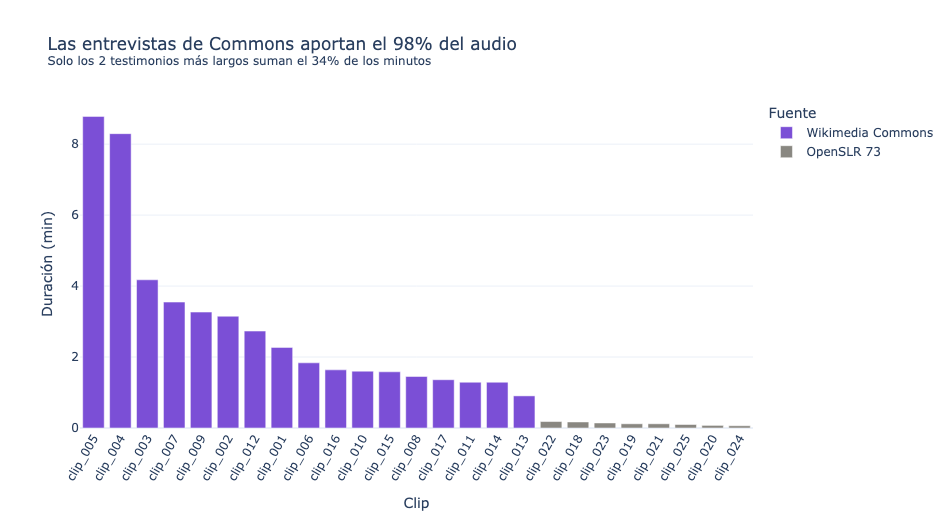

In [19]:
orden = clips.sort_values("duracion_seg", ascending=False)
pct_commons = 100 * clips.loc[clips["origen"] == "Wikimedia Commons", "minutos"].sum() / clips["minutos"].sum()
dos_mas_largos = orden.head(2)["minutos"].sum() / clips["minutos"].sum() * 100
fig = px.bar(orden, x="id", y="minutos", color="origen",
             color_discrete_map={"Wikimedia Commons": "#7b4fd6", "OpenSLR 73": "#898781"},
             hover_data=["descripcion", "n_hablantes"],
             labels={"id": "Clip", "minutos": "Duración (min)", "origen": "Fuente"},
             title=f"Las entrevistas de Commons aportan el {pct_commons:.0f}% del audio<br>"
                   f"<sup>Solo los 2 testimonios más largos suman el {dos_mas_largos:.0f}% de los minutos</sup>")
fig.update_xaxes(tickangle=-60)
fig.show()

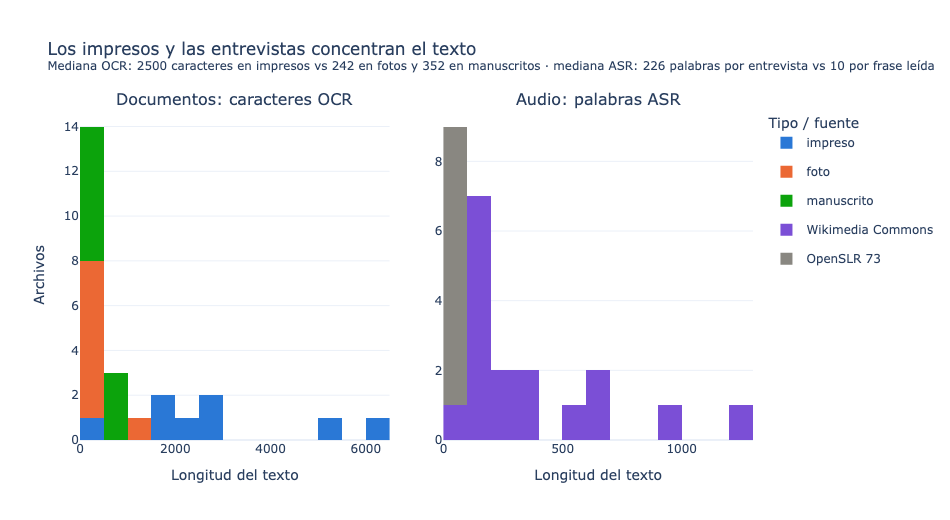

In [20]:
grafico_longitudes(docs, clips).show()

In [21]:
cols = ["id", "origen", "descripcion", "minutos", "palabras", "n_hablantes"]
vista = clips.assign(inicio_del_texto=clips["texto_asr"].str[:120])
print("Más largos:")
display(vista.nlargest(3, "duracion_seg")[cols + ["inicio_del_texto"]].round(1))
print("Más cortos:")
display(vista.nsmallest(3, "duracion_seg")[cols + ["inicio_del_texto"]].round(1))

Más largos:


,id,origen,descripcion,minutos,palabras,n_hablantes,inicio_del_texto
4,clip_005,Wikimedia Commons,Testimonio de una lideresa campesina de Junín (2024),8.8,1268,2,[HABLANTE_1] Mi nombre es [PERSONA_14]. [HABLANTE_2] ¿De dónde vienes y de cuál es tu ...
3,clip_004,Wikimedia Commons,Dirigente de la base Apurímac de Fenmucarinap (2022),8.3,983,2,"[HABLANTE_1] Bien, estamos en Plaza San Martín. Antes que nada, ¿me podría decir su no..."
2,clip_003,Wikimedia Commons,Dirigente de Fenmucarinap en conferencia de prensa (2022),4.2,618,2,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio ento...


Más cortos:


,id,origen,descripcion,minutos,palabras,n_hablantes,inicio_del_texto
23,clip_024,OpenSLR 73,"Frase leída, hombre (pem_05223_01286281629)",0.1,10,1,Quiero un lugar donde la música no esté tan fuerte
19,clip_020,OpenSLR 73,"Frase leída, mujer (pef_04310_02094324332)",0.1,8,1,La fiesta es para gente de la película
24,clip_025,OpenSLR 73,"Frase leída, hombre (pem_09334_01336449672)",0.1,9,1,No sé si te vaya a ver al rato.


In [22]:
# ejemplo de diarización: la entrevista con dos vendedoras en El Agustino (texto ya seudonimizado)
print((asr.SALIDAS / "clip_002.txt").read_text(encoding="utf-8")[:1500])

[00:00:00] [HABLANTE_1] Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entrevista acerca del fútbol como unión de masas. Estoy con las señoras...

[00:00:10] [HABLANTE_2] [PERSONA_8], soy [PERSONA_9].

[00:00:13] [HABLANTE_1] Muy bien, voy a comenzar con la primera pregunta y es, ¿qué expectativas tienen ante este partido?

[00:00:21] [HABLANTE_3] Que el afición se encuentra motivado para ganar este partido.

[00:00:30] [HABLANTE_1] ¿Me puede decir su nombre?

[00:00:32] [HABLANTE_3] [PERSONA_8]

[00:00:33] [HABLANTE_2] La perspectiva que yo pienso es que acá, que el Perú va a dar todo por todo, todo su corazón va a entregar para que ganemos, ¿no? Para que ganemos para ir a las Olimpiadas

[00:00:47] [HABLANTE_1] Al Mundial ¿Me puede decir su nombre?

[00:00:51] [HABLANTE_2] [PERSONA_9]

[00:00:52] [HABLANTE_1] Bien, sigo con la siguiente pregunta ¿Qué jugador piensa que va a ser el más determinante? Antes de que diga su respuesta, dígame su 

In [23]:
print("documentos.csv:", pd.read_csv(DATOS / "documentos.csv").shape)
print("transcripciones.csv:", pd.read_csv(DATOS / "transcripciones.csv").shape)
print("fuentes.csv:", fuentes.shape)
display(pd.read_csv(DATOS / "transcripciones.csv").head(5))
display(fuentes[["id", "modalidad", "fuente_url", "licencia", "acceso"]].head(5))

documentos.csv: (25, 7)
transcripciones.csv: (25, 8)
fuentes.csv: (50, 12)


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.wav,136.3,es,"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme s...","faster-whisper 1.2.1 large-v3-turbo (int8, CPU, VAD Silero on, beam 5, lang=es) + diar...",2,NaN
1,clip_002,datos/raw/audio/clip_002.wav,189.0,es,"[HABLANTE_1] Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa ...","faster-whisper 1.2.1 large-v3-turbo (int8, CPU, VAD Silero on, beam 5, lang=es) + diar...",3,NaN
2,clip_003,datos/raw/audio/clip_003.wav,250.6,es,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio ento...,"faster-whisper 1.2.1 large-v3-turbo (int8, CPU, VAD Silero on, beam 5, lang=es) + diar...",2,NaN
3,clip_004,datos/raw/audio/clip_004.wav,497.7,es,"[HABLANTE_1] Bien, estamos en Plaza San Martín. Antes que nada, ¿me podría decir su no...","faster-whisper 1.2.1 large-v3-turbo (int8, CPU, VAD Silero on, beam 5, lang=es) + diar...",2,NaN
4,clip_005,datos/raw/audio/clip_005.wav,526.9,es,[HABLANTE_1] Mi nombre es [PERSONA_14]. [HABLANTE_2] ¿De dónde vienes y de cuál es tu ...,"faster-whisper 1.2.1 large-v3-turbo (int8, CPU, VAD Silero on, beam 5, lang=es) + diar...",2,NaN


,id,modalidad,fuente_url,licencia,acceso
0,clip_001,audio,https://commons.wikimedia.org/wiki/File:Entrevista_1_en_la_Av._Rivag%C3%BCero_-_El_Agu...,CC BY-SA 4.0,Wikimedia Commons; reproducir con descargar_corpus.py
1,clip_002,audio,https://commons.wikimedia.org/wiki/File:Entrevista_2_en_la_Av._Rivag%C3%BCero_-_El_Agu...,CC BY-SA 4.0,Wikimedia Commons; reproducir con descargar_corpus.py
2,clip_003,audio,https://commons.wikimedia.org/wiki/File:Entrevista-Aurora_Coronado-organizaci%C3%B3n_d...,CC BY-SA 4.0,Wikimedia Commons; reproducir con descargar_corpus.py
3,clip_004,audio,https://commons.wikimedia.org/wiki/File:Entrevista_a_Luz_Merida-Organizaci%C3%B3n_de_m...,CC BY-SA 4.0,Wikimedia Commons; reproducir con descargar_corpus.py
4,clip_005,audio,https://commons.wikimedia.org/wiki/File:Testimonio_Lucinda_Quispealaya_-_Jun%C3%ADn.ogg,CC BY-SA 4.0,Wikimedia Commons; reproducir con descargar_corpus.py
